In [ ]:
from torch import nn
import torch
import torch.optim as optim
from torch.utils.data import Dataset,DataLoader
from torchvision import datasets,transforms

In [ ]:
transform = transforms.ToTensor() # image to tensor transformation

train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

# batch loading
train_loader = DataLoader(
    train_data, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_data, batch_size=64, shuffle=False
)

In [ ]:
print("Training images:", len(train_data))
print("Testing images:", len(test_data))

Training images: 60000
Testing images: 10000


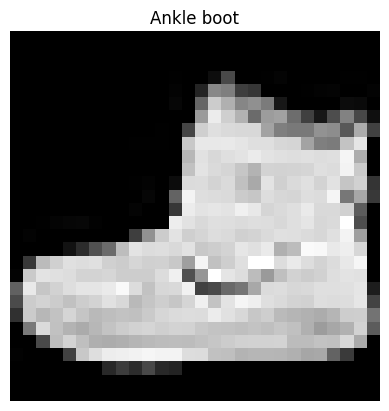

Image shape: torch.Size([1, 28, 28])
Label: 9 - Ankle boot


In [ ]:
import matplotlib.pyplot as plt
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

image, label = train_data[0]
img = mpimg.imread(image)
plt.imshow(image.squeeze())
plt.title(class_names[label])
plt.axis("off")
plt.show()

print("Image shape:", image.shape)
print("Label:", label, "-", class_names[label])

In [ ]:
from torch.nn.modules.dropout import Dropout
class CNN(nn.Module):
  def __init__(self):
    super().__init__()

    self.features = nn.Sequential(

        nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3,
            padding = 1
        ),

        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,stride = 2),

        nn.Conv2d(
            in_channels=32,
            out_channels = 64,
            kernel_size=3,
            padding = 1
        ),

        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,stride=2)
    )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64*7*7,128),
        nn.ReLU(),
        nn.Dropout(p=0.3),
        nn.Linear(128,10)
    )
  def forward(self,x):
      x = self.features(x)
      x = self.classifier(x)
      return x

In [ ]:
model = CNN()

criterion = nn.CrossEntropyLoss() # loss function
optimizer = optim.Adam(model.parameters(),lr=0.001) # optimizer

In [ ]:
epochs = 5

for epoch in range(epochs):
  model.train()
  running_loss = 0.0

  for images, lables in train_loader:
    # forward pass
    output = model(images)
    # loss calculate
    loss = criterion(output,lables)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

avg_loss = running_loss / len(train_loader)
print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {avg_loss:.4f}"
    )


Epoch [5/5], Loss: 0.2418


In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
  for images,labels in test_loader:
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

    total += labels.size(0)
    correct += (predictions == labels).sum().item()

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 91.04%


In [ ]:
image, true_lable = test_data[0]

model.eval()
with torch.no_grad():
  output = model(image.unsqueeze(0))
  predicted_lable = output.argmax(dim=1).item()

print("Predicted class:", class_names[predicted_lable])
print("Actual class:", class_names[true_lable])

Predicted class: Ankle boot
Actual class: Ankle boot
